# STAR Project – Exploring the Data

**Research question:** Does the benefit of small classes (K–3) last over time, up to grade 8 and high school?

**Data:** Project STAR, Tennessee 1985–1989. Harvard Dataverse (hdl:1902.1/10766).
Each row is one student. Put `STAR_Students.sav` in `data/raw/` before running.

## 1. Setup and load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 50)

df = pd.read_spss("../data/raw/STAR_Students.sav")
df = df.copy()  # makes the table faster to work with (removes a warning)
print(df.shape)  # (rows, columns)
df.head()

(11601, 379)


,stdntid,gender,race,birthmonth,birthday,birthyear,FLAGSGK,FLAGSG1,FLAGSG2,FLAGSG3,flaggk,flagg1,flagg2,flagg3,flagg4,flagg5,flagg6,flagg7,flagg8,flagprt4,flagidn8,flagprt8,flagsatact,flaghscourse,flaghsgraduate,...,hsciento,hsgpaflang,hsgpamath,hsgpascience,hsgpaoverall,hslvlfla,hslvlmth,hsyrscor,hsctsrc,hssat,hsact,hstest,hssatmath,hssatverbal,hssattot,hsactcomp,hsacttot,hsactenglish,hsactmath,hsactread,hsactscience,hssatconverted,hsactconverted,hsgrdadd,hsgrdcol
0,10000.0,MALE,WHITE,JANUARY,22.0,1979.0,NO,YES,YES,YES,NO,YES,YES,YES,YES,YES,NO,NO,NO,YES,NO,NO,NO,NO,NO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO,NO,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10001.0,MALE,WHITE,FEBRUARY,20.0,1980.0,YES,NO,NO,NO,NO,NO,NO,NO,NO,NO,YES,YES,YES,NO,NO,NO,NO,NO,NO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO,NO,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10002.0,FEMALE,BLACK,JULY,21.0,1979.0,NO,NO,NO,YES,NO,NO,NO,YES,YES,NO,YES,YES,YES,NO,NO,NO,NO,NO,YES,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO,NO,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DROPPED OUT,NO
3,10003.0,MALE,WHITE,MAY,28.0,1980.0,NO,YES,YES,YES,NO,YES,YES,YES,YES,NO,YES,NO,YES,YES,NO,NO,YES,YES,YES,...,4.0,75.0,78.33,75.0,83.18,NaN,3.0,3 years of course taking data,Transcript,YES,YES,YES,410.0,450.0,860.0,22.0,89.0,16.0,21.0,28.0,24.0,860.0,22.0,GRADUATED,YES
4,10004.0,FEMALE,BLACK,JANUARY,2.0,1980.0,NO,NO,YES,YES,NO,NO,YES,YES,YES,NO,YES,YES,YES,NO,NO,NO,NO,NO,YES,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO,NO,NO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,DROPPED OUT,NO


## 2. Get to know the variables

Most column names start with the grade: `gk` = kindergarten, `g1`–`g8` = grades 1–8, `hs` = high school.

What we found:
- **Class type** exists only for K–3 (`gkclasstype` … `g3classtype`). This is when the experiment ran.
- **Main math score:** `tmathss` (total math scaled score). It exists in every grade, K to 8.
- High school has no `tmathss`. It has SAT, ACT and GPA instead.

In [2]:
grades = ["gk", "g1", "g2", "g3", "g4", "g5", "g6", "g7", "g8"]
k3 = ["gk", "g1", "g2", "g3"]

# number of columns per grade
for p in grades + ["hs"]:
    cols = [c for c in df.columns if c.lower().startswith(p)]
    print(p, len(cols))

print("\nClass type:", [c for c in df.columns if "classtype" in c.lower()])
print("Math:", [c for c in df.columns if "math" in c.lower()])

gk 22
g1 28
g2 25
g3 35
g4 62
g5 17
g6 8
g7 17
g8 82
hs 54

Class type: ['gkclasstype', 'g1classtype', 'g2classtype', 'g3classtype']
Math: ['gktmathss', 'g1tmathss', 'g1mathbsraw', 'g1mathbsobjraw', 'g1mathbsobjpct', 'g2tmathss', 'g2mathbsraw', 'g2mathbsobjraw', 'g2mathbsobjpct', 'g3tmathss', 'g3mathcomputss', 'g3mathnumconcss', 'g3mathapplss', 'g3mathbsraw', 'g3mathbsobjraw', 'g3mathbsobjpct', 'g4tmathss', 'g4mathcomputss', 'g4mathconcapplss', 'g4mathbsobjraw', 'g5tmathss', 'g5mathcomputss', 'g5mathconcapplss', 'g5mathbsobjraw', 'g6tmathss', 'g6mathbsobjraw', 'g7tmathss', 'g7mathcomputss', 'g7mathconcapplss', 'g7mathbsobjraw', 'g8tmathss', 'g8mathco', 'g8math_a', 'g8mathbsobjraw', 'hsmath1', 'hsmath2', 'hsmath3', 'hsmath4', 'hsmath5', 'hsmathtotsem', 'hsgpamath', 'hssatmath', 'hsactmath']


## 3. Class type in each grade

How many students were in each class type, in each grade? `NaN` = not in the study that year.

In [3]:
class_counts = pd.DataFrame(
    {g: df[f"{g}classtype"].value_counts(dropna=False) for g in k3}
)
class_counts

,gk,g1,g2,g3
REGULAR + AIDE CLASS,2231,2320,2495,2543
REGULAR CLASS,2194,2584,2329,2085
SMALL CLASS,1900,1925,2016,2174
NaN,5276,4772,4761,4799


## 4. How many students do we have in each grade?

We count students with a math score in each grade.
No score = the student was not tested that year (left the study, or joined later).

gk    5871
g1    6598
g2    6065
g3    6077
g4    4331
g5    2589
g6    6422
g7    4888
g8    6213
dtype: int64


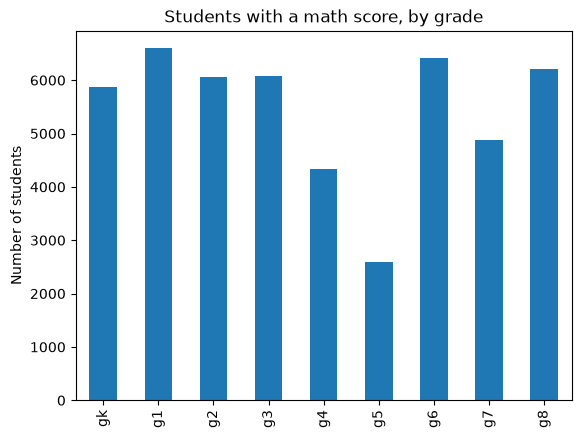

In [4]:
n_scores = pd.Series({g: df[f"{g}tmathss"].notna().sum() for g in grades})
print(n_scores)

n_scores.plot(kind="bar", title="Students with a math score, by grade")
plt.ylabel("Number of students")
plt.show()

## 5. Average math score by class type

Some students joined in grade 1, 2 or 3, so they have no K class type.
We give each student their **first** class type (the first grade they appear in K–3).

Note: K–3 and 4–8 used different tests, so scores jump between grade 3 and 4.
Compare the class types **within** a grade, not across grades.

In [5]:
classtype_cols = [f"{g}classtype" for g in k3]
df["first_classtype"] = df[classtype_cols].astype(object).bfill(axis=1).iloc[:, 0]

print(df["first_classtype"].value_counts(dropna=False), "\n")

means = pd.DataFrame(
    {g: df.groupby("first_classtype")[f"{g}tmathss"].mean() for g in grades}
).T.round(1)
means

first_classtype
REGULAR CLASS           4328
REGULAR + AIDE CLASS    4249
SMALL CLASS             3024
Name: count, dtype: int64 



first_classtype,REGULAR + AIDE CLASS,REGULAR CLASS,SMALL CLASS
gk,482.8,483.2,490.9
g1,528.8,526.7,538.4
g2,578.0,578.8,587.0
g3,615.2,616.9,623.3
g4,703.9,707.2,710.6
g5,731.8,733.9,739.1
g6,750.7,751.1,754.7
g7,763.3,764.0,770.3
g8,779.8,782.2,786.0


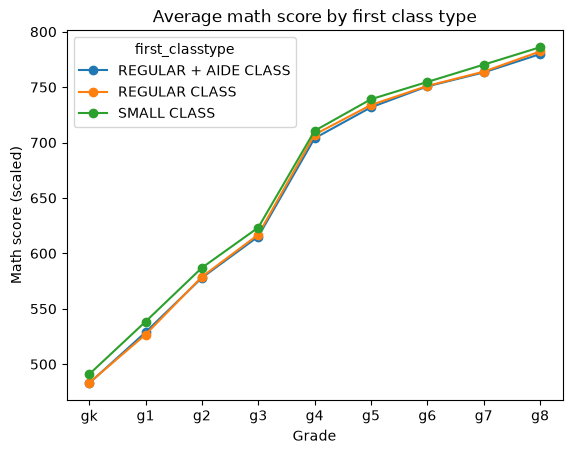

In [6]:
means.plot(marker="o", title="Average math score by first class type")
plt.xlabel("Grade")
plt.ylabel("Math score (scaled)")
plt.show()

## 6. Score distributions

Histograms of the math score in kindergarten and grade 8, by class type.

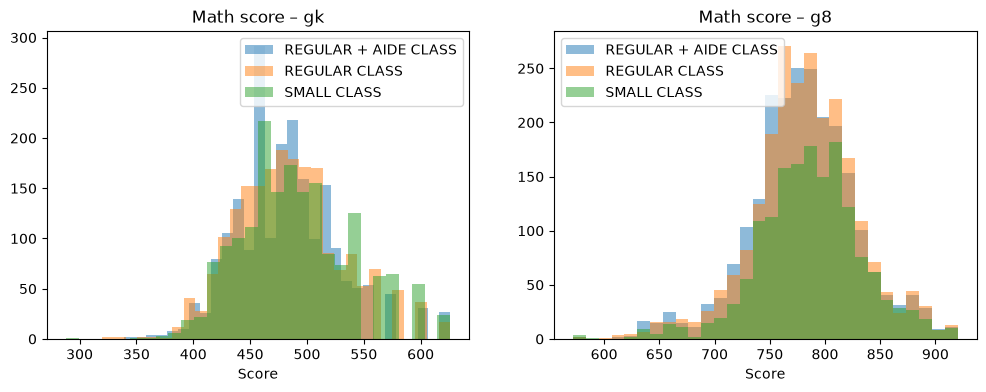

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, g in zip(axes, ["gk", "g8"]):
    for ctype, group in df.groupby("first_classtype"):
        ax.hist(group[f"{g}tmathss"].dropna(), bins=30, alpha=0.5, label=ctype)
    ax.set_title(f"Math score – {g}")
    ax.set_xlabel("Score")
    ax.legend()

plt.show()

## 7. Complications to keep in mind

1. **Missing data:** what share of students have no score in each grade?
2. **Switching:** did students stay in the class type they got in K? (rows = K, columns = grade 1)

In [8]:
missing = (df[[f"{g}tmathss" for g in grades]].isna().mean() * 100).round(1)
print("Percent missing math score:")
print(missing, "\n")

pd.crosstab(df["gkclasstype"], df["g1classtype"], dropna=False)

Percent missing math score:
gktmathss    49.4
g1tmathss    43.1
g2tmathss    47.7
g3tmathss    47.6
g4tmathss    62.7
g5tmathss    77.7
g6tmathss    44.6
g7tmathss    57.9
g8tmathss    46.4
dtype: float64 



g1classtype,REGULAR + AIDE CLASS,REGULAR CLASS,SMALL CLASS
gkclasstype,,,
NaN,903,1026,385
REGULAR + AIDE CLASS,706,761,122
REGULAR CLASS,663,737,126
SMALL CLASS,48,60,1292


## 8. Simple ANOVA: kindergarten

Is the average K math score different between the three class types?
This is a first check only. It ignores schools (randomization was done within schools).

In [9]:
k_data = df[["gkclasstype", "gktmathss"]].dropna()
groups = [g["gktmathss"] for _, g in k_data.groupby("gkclasstype", observed=True)]

print(k_data.groupby("gkclasstype", observed=True)["gktmathss"].agg(["count", "mean", "std"]).round(1))

f_stat, p_value = stats.f_oneway(*groups)
print(f"\nF = {f_stat:.2f}, p = {p_value:.4g}")

                      count   mean   std
gkclasstype                             
REGULAR + AIDE CLASS   2077  482.8  45.8
REGULAR CLASS          2032  483.2  47.6
SMALL CLASS            1762  490.9  49.5

F = 17.20, p = 3.565e-08


## 9. Who are the students?

Basic background: gender, race, free lunch (a proxy for low income) and school location.
Free lunch and location are taken from kindergarten.

In [10]:
background = ["gender", "race", "gkfreelunch", "gksurban"]

for col in background:
    if col in df.columns:
        pct = (df[col].value_counts(dropna=False, normalize=True) * 100).round(1)
        print(f"--- {col} (%) ---")
        print(pct, "\n")

--- gender (%) ---
gender
MALE      52.8
FEMALE    47.0
NaN        0.2
Name: proportion, dtype: float64 

--- race (%) ---
race
WHITE              62.1
BLACK              36.0
NaN                 1.2
ASIAN               0.3
HISPANIC            0.2
OTHER               0.2
NATIVE AMERICAN     0.1
Name: proportion, dtype: float64 

--- gkfreelunch (%) ---
gkfreelunch
NaN               45.7
NON-FREE LUNCH    28.0
FREE LUNCH        26.3
Name: proportion, dtype: float64 

--- gksurban (%) ---
gksurban
NaN           45.5
RURAL         25.1
INNER CITY    12.3
SUBURBAN      12.2
URBAN          4.9
Name: proportion, dtype: float64 



## 10. Schools, teachers and class size

How many schools and kindergarten classes are there?
Did small classes really have 13–17 students, and regular classes 22–25?

Schools in K: 79
Teachers (classes) in K: 325 

                       count  mean  std   min   25%   50%   75%   max
gkclasstype                                                          
REGULAR + AIDE CLASS  2231.0  22.8  2.3  15.0  22.0  23.0  24.0  28.0
REGULAR CLASS         2194.0  22.4  2.1  16.0  21.0  23.0  24.0  27.0
SMALL CLASS           1900.0  15.1  1.5  12.0  14.0  15.0  16.0  17.0


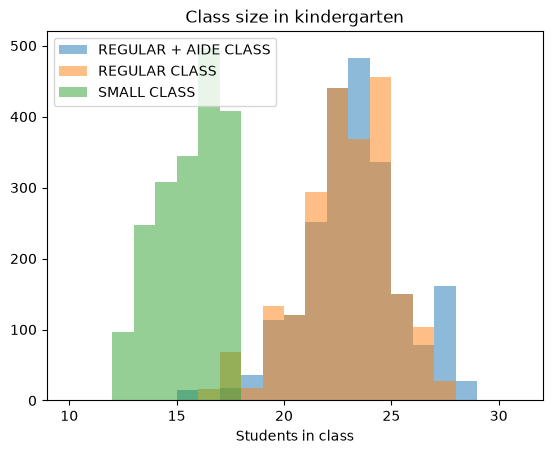

In [11]:
print("Schools in K:", df["gkschid"].nunique())
print("Teachers (classes) in K:", df["gktchid"].nunique(), "\n")

print(df.groupby("gkclasstype", observed=True)["gkclasssize"].describe().round(1))

for ctype, group in df.groupby("gkclasstype", observed=True):
    plt.hist(group["gkclasssize"].dropna(), bins=range(10, 32), alpha=0.5, label=ctype)
plt.title("Class size in kindergarten")
plt.xlabel("Students in class")
plt.legend()
plt.show()

## 11. How stable are scores over time?

Correlation between a student's math score in different grades.
High correlation = students who do well early tend to keep doing well.

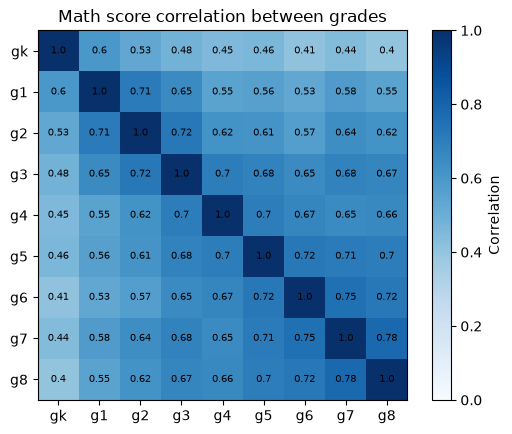

Math vs reading in K: 0.71


In [12]:
math_cols = [f"{g}tmathss" for g in grades]
corr = df[math_cols].corr().round(2)
corr.index = corr.columns = grades

plt.imshow(corr, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(grades)), grades)
plt.yticks(range(len(grades)), grades)
for i in range(len(grades)):
    for j in range(len(grades)):
        plt.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=7)
plt.title("Math score correlation between grades")
plt.show()

# math vs reading in the same grade
if "gktreadss" in df.columns:
    print("Math vs reading in K:", round(df["gktmathss"].corr(df["gktreadss"]), 2))

## Notes

_Write here what you noticed: surprises, questions, things to check later._

**Threads worth following:**
-